In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
from pygam import LinearGAM, s
import matplotlib.pyplot as plt

from datetime import datetime

import sys
sys.path.append("../../tools")
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(acht)


In [ ]:
def extract_gamma_real_matrix(Xnum_pad, n_real, max_species):
    
    datasize = Xnum_pad.shape[0]
    featgam_max = max_species * (max_species - 1)
    gamma_flat = Xnum_pad[:, max_species:max_species + featgam_max]
    gamma_mat = np.zeros((datasize, max_species, max_species))

    idx = 0
    for i in range(max_species):
        for j in range(max_species):
            if i != j:
                gamma_mat[:, i, j] = gamma_flat[:, idx]
                idx += 1

    sub_mat = gamma_mat[:, :n_real, :n_real] 

    return sub_mat 

def compute_interaction_type_ratios(sub_mat, tol=1e-12):
    """
    sub_mat: (N, S, S)
    return: (N, 6) -> [++, +-, +0, --, -0, 00]
    """

    N, S, _ = sub_mat.shape
    results = np.zeros((N, 6))

    triu_idx = np.triu_indices(S, k=1)

    for i in range(N):
        M = sub_mat[i]

        a = M[triu_idx]               # M[p, q]
        b = M.T[triu_idx]            # M[q, p]

        def sign(x):
            s = np.zeros_like(x)
            s[x > tol] = 1
            s[x < -tol] = -1
            return s

        sa = sign(a)
        sb = sign(b)

        total = len(sa)

        pp = np.sum((sa == 1) & (sb == 1))
        pm = np.sum((sa * sb == -1))
        p0 = np.sum(((sa == 1) & (sb == 0)) | ((sa == 0) & (sb == 1)))
        mm = np.sum((sa == -1) & (sb == -1))
        m0 = np.sum(((sa == -1) & (sb == 0)) | ((sa == 0) & (sb == -1)))
        zz = np.sum((sa == 0) & (sb == 0))

        results[i] = np.array([pp, pm, p0, mm, m0, zz]) / total

    return results


In [4]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
MaxNum = emodel["NumSpecies"]
featgam2 = MaxNum**2-MaxNum


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
df = pd.read_csv("../Fig4/gamma5.csv")
df = df.dropna()
#datasize = 6000


In [6]:
#sub_df = df[df["richness"]>=4]
sub_df = df[df["richness"]==10]
#sub_df = sub_df.sample(n=datasize, random_state=42)

sub_df["relative_H"] = sub_df["relative_H"].clip(lower=0, upper=1)
sub_df["relative_D"] = sub_df["relative_D"].clip(lower=0, upper=1)


C:\Users\HW\AppData\Local\Temp\ipykernel_8916\3369733485.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_df["relative_H"] = sub_df["relative_H"].clip(lower=0, upper=1)
C:\Users\HW\AppData\Local\Temp\ipykernel_8916\3369733485.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_df["relative_D"] = sub_df["relative_D"].clip(lower=0, upper=1)


In [7]:
Xnum_pad = []
interaction_ratios = []
relative_H = []
relative_D = []

for spe, subsub in sub_df.groupby("richness"):

    ss_X_pad = subsub.iloc[ :, :(MaxNum**2+MaxNum)].values
    ss_mat = extract_gamma_real_matrix(ss_X_pad, int(spe), MaxNum)
    ss_ratios = compute_interaction_type_ratios(ss_mat) # size=(datasize, 6)
    ss_H = subsub["relative_H"].values
    ss_D = subsub["relative_D"].values

    Xnum_pad.append(ss_X_pad)
    interaction_ratios.append(ss_ratios)
    relative_H.append(ss_H)
    relative_D.append(ss_D)

Xnum_pad = np.concatenate(Xnum_pad)
interaction_ratios = np.concatenate(interaction_ratios)
relative_H = np.concatenate(relative_H)
relative_D = np.concatenate(relative_D)


In [ ]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

colors = ['#683a2a', '#c2732c', '#a34e3c', '#7cadb8',  '#9ca47b', '#efc9a8' ]
labels = ["+/+", "+/-", "+/0", "-/-", "-/0", "0/0"]


In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import r2_score
import numpy as np

for k in range(6):
    ratio = interaction_ratios[:, k]

    cmap = LinearSegmentedColormap.from_list(
        "custom_cmap",
        ["#f3f3f3", colors[k]]
    )

    plotx = relative_D
    ploty = ratio

    plt.figure(figsize=(1,1), dpi=200)

    hb = plt.hexbin(
        plotx,
        ploty,
        gridsize=25, # number of hexagons
        #extent=(-0.1, 1.1, -0.1, 1.1),   # xmin, xmax, ymin, ymax
        mincnt=1, # minimum count in each hexagon
        cmap=cmap,
        vmin=0,
        vmax=50, # maximum count in each hexagon
        edgecolors='none',
        # alpha=0.8,
        rasterized=True
    )

    spear, spear_p = spearmanr(plotx, ploty)
    pear, pear_p = pearsonr(plotx, ploty)
    r2 = r2_score(plotx, ploty)

    print(f"Spearman's rho: {spear}, p-value: {spear_p}")
    print(f"Pearson's r: {pear}, p-value: {pear_p}")
    print(f"r2: {r2}")

    # cbar = plt.colorbar(hb)
    # cbar.set_label("Count")

    # plt.xlim(-0.1, 1.1)
    # plt.ylim(-0.1, 1.1)
    plt.xlabel(r"$\mathcal{D}$")
    plt.ylabel(labels[k])
    plt.tick_params(direction='in')
    #plt.savefig(f"6type_scatter_H_sp10_{k}.pdf", dpi=1000, bbox_inches='tight')
    plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.optimize import curve_fit
from sklearn.preprocessing import StandardScaler
from matplotlib.ticker import FormatStrFormatter

x = np.asarray(relative_D, dtype=float) 
y = np.asarray(interaction_ratios[:, 3], dtype=float) 

valid = np.isfinite(x) & np.isfinite(y)
x, y = x[valid], y[valid]

xy = np.column_stack([x, y])
scaler = StandardScaler()
z = scaler.fit_transform(xy)

kde = gaussian_kde(z.T)
density = kde(z.T)

keep_fraction = 1
density_threshold = np.quantile(density, 1 - keep_fraction)
keep = density >= density_threshold

xf, yf = x[keep], y[keep]

print(f"Original points: {len(x)}")
print(f"Retained points: {len(xf)}")
print(f"Removal ratio: {1 - keep.mean():.1%}")

edges = np.linspace(x.min(), x.max(), 31)
xc, yc = [], []

for i in range(len(edges) - 1):
    idx = (
        (xf >= edges[i]) &
        (xf < edges[i + 1] if i < len(edges) - 2
         else xf <= edges[i + 1])
    )

    if idx.sum() >= 5:
        xc.append(np.median(xf[idx]))
        yc.append(np.median(yf[idx]))

xc = np.asarray(xc)
yc = np.asarray(yc)

def exp_decay(x, a, k, c):
    return c + a * np.exp(-k * x)

popt, pcov = curve_fit(
    exp_decay,
    xc, yc,
    p0=[max(yc.max() - yc.min(), 1e-3), 5.0, max(0, yc.min())],
    bounds=([0, 0, 0], [2, 100, 1]),
    maxfev=30000,
)

a, k, c = popt
print(f"a = {a:.4f}")
print(f"k = {k:.4f}")
print(f"c = {c:.4f}")

xx = np.linspace(0.05, x.max(), 500)

fig, ax = plt.subplots(figsize=(1, 1), dpi=200)

ax.scatter(x[~keep], y[~keep], s=5, c="#E1E1E1",
           alpha=0.4, label="Filtered points", rasterized=True)
ax.scatter(xf, yf, s=5, c='#7cadb8',
           alpha=0.35, label="Retained points", rasterized=True)

ax.plot(xx, exp_decay(xx, *popt), c="#D1495B",
        lw=1, label="Exponential fit",
)

ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

ax.set_xlabel(r"$D$")
ax.set_ylabel(r"Competition ratio (-/-)")
ax.legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.2),
    ncol=1
)
ax.tick_params(direction='in',)

plt.savefig(f"6type_competition-D_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True)

#print("Fit parameters a, b, p, c =", popt)
print("Exponential fit parameters a, k, c =", popt)


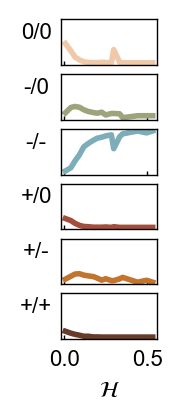

Subplot 0: (-0.020077578402265747, 0.5591093525137554)
Subplot 1: (-0.020077578402265747, 0.5591093525137554)
Subplot 2: (-0.020077578402265747, 0.5591093525137554)
Subplot 3: (-0.020077578402265747, 0.5591093525137554)
Subplot 4: (-0.020077578402265747, 0.5591093525137554)
Subplot 5: (-0.020077578402265747, 0.5591093525137554)


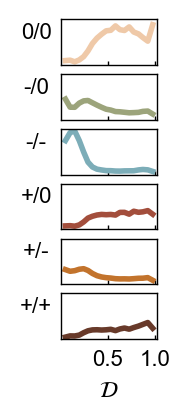

Subplot 0: (0.0042412201357311455, 1.0265300792315635)
Subplot 1: (0.0042412201357311455, 1.0265300792315635)
Subplot 2: (0.0042412201357311455, 1.0265300792315635)
Subplot 3: (0.0042412201357311455, 1.0265300792315635)
Subplot 4: (0.0042412201357311455, 1.0265300792315635)
Subplot 5: (0.0042412201357311455, 1.0265300792315635)


In [ ]:
def six_inter_type_line(emer_property, emer_type="relative_H",):

    # Six configurations: plot separate lines
    fig, axes = plt.subplots(6, 1, figsize=(0.8, 1.6), sharey=True, sharex=True, dpi=200)

    for k, ax in enumerate(axes[::-1]):

        # Current interaction ratio
        ratio = interaction_ratios[:, k]

        # Sort by ratio ascending
        sort_idx = np.argsort(ratio)

        ratio_sorted = ratio[sort_idx]
        emer_sorted = emer_property[sort_idx]

        # Directly connect original data points
        ax.plot(
            ratio_sorted,
            emer_sorted,
            lw=0.6,
            color=colors[k]
        )

        ax.set_ylabel(labels[k], rotation=0, labelpad=9)

        ax.tick_params(direction="in")

        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)

        # Only show bottom X tick labels
        if ax is not axes[-1]:
            ax.tick_params(labelbottom=False)

        # Hide Y ticks
        ax.set_yticks([])

    # 4. Overall layout
    fig.subplots_adjust(
        left=0.4,
        right=1,
        bottom=0,
        top=1,
        # wspace=0.05, # Horizontal spacing between subplots
        # hspace=0.05 # Vertical spacing between subplots
    )

    axes[-1].set_xlabel("Interaction ratio")

    if emer_type == "relative_H":
        ylabel_name = r"$\mathcal{H}$"
    elif emer_type == "relative_D":
        ylabel_name = r"$\mathcal{D}$"

    fig.supylabel(ylabel_name, x=0)

    plt.savefig(
        f"6type_line_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
        dpi=1000,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()

def six_inter_type_line2(emer_property, emer_type="relative_H", num_bins=20):

    # Six configurations: plot separate lines
    fig, axes = plt.subplots(
        6, 1,
        figsize=(0.8, 1.6),
        sharey=True,
        sharex=True,
        dpi=200
    )

    for k, ax in enumerate(axes[::-1]):

        # Current interaction ratio
        ratio = interaction_ratios[:, k]

        # Equal-width binning
        bins = np.linspace(0, 1, num_bins + 1)

        bin_x = []
        bin_y = []

        for i in range(num_bins):

            # Current bin
            if i < num_bins - 1:
                mask = (ratio >= bins[i]) & (ratio < bins[i + 1])
            else:
                mask = (ratio >= bins[i]) & (ratio <= bins[i + 1])

            # Only compute if bin has data
            if np.sum(mask) > 0:

                # x: mean ratio in this bin
                x_mean = np.mean(ratio[mask])

                # y: mean emergent property in this bin
                y_mean = np.mean(emer_property[mask])

                bin_x.append(x_mean)
                bin_y.append(y_mean)

        bin_x = np.array(bin_x)
        bin_y = np.array(bin_y)

        # Connect bin means
        ax.plot(
            bin_x,
            bin_y,
            lw=2,
            color=colors[k]
        )

        ax.set_ylabel(
            labels[k],
            rotation=0,
            labelpad=9
        )

        ax.tick_params(direction="in")

        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)

        # Only show bottom X tick labels
        if ax is not axes[-1]:
            ax.tick_params(labelbottom=False)

        # Hide Y ticks
        ax.set_yticks([])

    fig.subplots_adjust(
        left=0.4,
        right=1,
        bottom=0,
        top=1,
    )

    axes[-1].set_xlabel("Interaction ratio")

    if emer_type == "relative_H":
        ylabel_name = r"$\mathcal{H}$"
    elif emer_type == "relative_D":
        ylabel_name = r"$\mathcal{D}$"

    fig.supylabel(ylabel_name, x=0)

    plt.savefig(
        f"6type_line_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
        dpi=1000,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()

def six_inter_type_line3(emer_property, emer_type="relative_H", num_bins=20):

    # Equal-width binning over actual emergent property range
    emer_min = emer_property.min()
    emer_max = emer_property.max()

    bin_edges = np.linspace(emer_min, emer_max, num_bins + 1)

    # Which bin each sample belongs to
    bin_idx = np.digitize(emer_property, bin_edges) - 1
    # Prevent max from falling into num_bins
    bin_idx = np.clip(bin_idx, 0, num_bins - 1)

    # Compute emergent property center for each bin
    # This x is shared by all six interaction types

    emer_centers = []
    bin_counts = []

    for i in range(num_bins):

        mask = bin_idx == i

        # Skip bins with no samples
        if not np.any(mask):
            continue

        # Actual mean of emergent property in current bin
        emer_centers.append(np.mean(emer_property[mask]))
        bin_counts.append(np.sum(mask))

    emer_centers = np.array(emer_centers)
    bin_counts = np.array(bin_counts)

    # Compute ratio for each of six interaction types
    fig, axes = plt.subplots(6, 1, figsize=(0.8, 1.6), sharey=True, sharex=True, dpi=200)

    for k, ax in enumerate(axes[::-1]):

        # Current interaction ratio
        ratio = interaction_ratios[:, k]
        ratio_binned = []

        for i in range(num_bins):

            mask = bin_idx == i

            # Skip bins with no samples
            if not np.any(mask):
                continue

            # In current emergent-property bin:
            # Mean of interaction ratio
            ratio_mean = np.mean(ratio[mask])
            ratio_binned.append(ratio_mean)

        ratio_binned = np.array(ratio_binned)

        # Plot interaction ratio vs emergent property
        ax.plot(emer_centers, ratio_binned, lw=2, color=colors[k])
        ax.set_ylabel(labels[k], rotation=0, labelpad=9)

        ax.tick_params(direction="in")
        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)

        # Only show bottom X tick labels
        if ax is not axes[-1]:
            ax.tick_params(labelbottom=False)

        # Hide Y ticks
        ax.set_yticks([])

    # Unified X-axis as emergent property
    if emer_type == "relative_H":
        xlabel_name = r"$\mathcal{H}$"

    elif emer_type == "relative_D":
        xlabel_name = r"$\mathcal{D}$"

    axes[-1].set_xlabel(xlabel_name)

    fig.subplots_adjust(
        left=0.4,
        right=1,
        bottom=0,
        top=1,
        # wspace=0.05, # Horizontal spacing between subplots
        # hspace=0.05 # Vertical spacing between subplots
    )
    
    plt.savefig(
        f"6type_line_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
        dpi=1000,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()
    for i, ax in enumerate(axes):
        print(f"Subplot {i}: {ax.get_xlim()}")

six_inter_type_line3(relative_H, emer_type="relative_H",)
six_inter_type_line3(relative_D, emer_type="relative_D",)


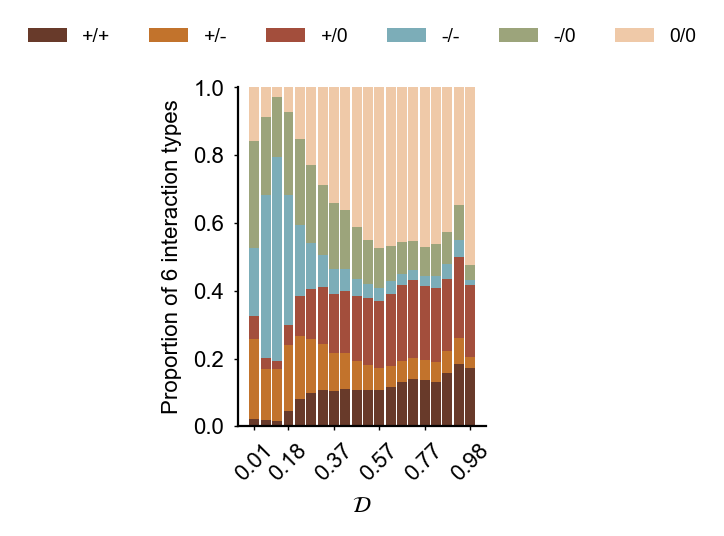

In [15]:
def six_inter_type_proportion_draw(emer_property, emer_type="relative_H", num_bins=20,):
    # 1. Equal-width binning over actual range of H

    emer_min = emer_property.min()
    emer_max = emer_property.max()

    bin_edges = np.linspace(emer_min, emer_max, num_bins + 1)

    # Which bin each sample belongs to
    bin_idx = np.digitize(emer_property, bin_edges) - 1

    # Prevent max from falling into num_bins
    bin_idx = np.clip(bin_idx, 0, num_bins - 1)

    # 2. Aggregate each bin
    ratios_binned = []
    emer_centers = []
    bin_counts = []

    for i in range(num_bins):

        mask = bin_idx == i
        # Skip bins with no samples
        if not np.any(mask):
            continue
        # H of current bin
        emer_centers.append(np.mean(emer_property[mask]))
        # Six interaction ratios of current bin
        ratios_binned.append(np.mean(interaction_ratios[mask], axis=0))
        # Sample count
        bin_counts.append(np.sum(mask))


    # Convert to array
    emer_centers = np.array(emer_centers)
    ratios_binned = np.array(ratios_binned)
    bin_counts = np.array(bin_counts)

    # 3. Draw bars at discrete positions
    num_valid_bins = len(emer_centers)
    x = np.arange(num_valid_bins)
    bottom = np.zeros(num_valid_bins)

    fig, ax = plt.subplots(figsize=(1.6, 2.2), dpi=200)

    # 4. Stacked bars
    for i in range(6):

        ax.bar(
            x,
            ratios_binned[:, i],
            bottom=bottom,
            width=0.88,
            color=colors[i],
            label=labels[i],
            linewidth=0
        )

        bottom += ratios_binned[:, i]

    # 5. X tick
    # Show only 6 labels
    tick_idx = np.linspace(0, num_valid_bins - 1, 6, dtype=int)

    ax.set_xticks(tick_idx)

    ax.set_xticklabels(
        [
            f"{emer_centers[i]:.2f}"
            for i in tick_idx
        ],
        rotation=45
    )

    # 6. Beautify
    if emer_type == "relative_H":
        xlabel_name = r"$\mathcal{H}$"
    elif emer_type == "relative_D":
        xlabel_name = r"$\mathcal{D}$"

    ax.set_xlabel(xlabel_name)
    ax.set_ylabel("Proportion of 6 interaction types")

    ax.set_ylim(0, 1)

    ax.grid(False)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_linewidth(0.8)
    ax.spines['bottom'].set_linewidth(0.8)

    # 7. Legend
    ax.legend(
        ncol=6,
        bbox_to_anchor=(0.5, 1.15),
        loc="center",
        frameon=False
    )

    plt.savefig(
        f"6type_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
        dpi=1000,
        bbox_inches='tight',
        transparent=True
    )

    plt.show()

#six_inter_type_proportion_draw(relative_H, "relative_H")
six_inter_type_proportion_draw(relative_D, "relative_D")
